# Tracking a moving object with frame differences

A grayscale video is a stack of image matrices, so it fits in one 3-D array with shape (frames, rows, cols).
If the camera holds still, subtracting one frame from the next leaves only the pixels that changed, which is where something moved.
Here we use a short clip of a Newton's cradle, a standard public-domain test animation from the imageio library. At any moment only one end ball is swinging.

In [1]:
%matplotlib widget
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageSequence

## Load the video

The file is an animated GIF. We convert each frame to grayscale, turn it into a matrix, and stack the matrices into one array. Converting to `float` matters: subtracting `uint8` values wraps around instead of going negative.

In [2]:
gif = Image.open("newtonscradle.gif")
video = np.array([np.array(frame.convert("L")) for frame in ImageSequence.Iterator(gif)])
video = video.astype(float)

n_frames, n_rows, n_cols = video.shape
print("video shape (frames, rows, cols):", video.shape)

video shape (frames, rows, cols): (36, 150, 200)


Each `video[k]` is one ordinary image matrix. Here are a few of them.

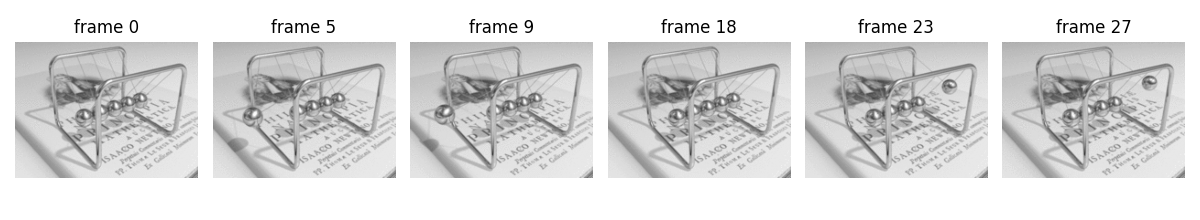

In [3]:
show = [0, 5, 9, 18, 23, 27]
fig, axes = plt.subplots(1, len(show), figsize=(12, 2.2))
for ax, k in zip(axes, show):
    ax.imshow(video[k], cmap="gray", vmin=0, vmax=255)
    ax.set_title(f"frame {k}")
    ax.axis("off")
fig.tight_layout()

## Difference successive frames

`np.diff(video, axis=0)` subtracts each frame from the next. The frame, the book and the resting balls cancel, and the absolute value keeps both brightening and darkening pixels.

diff shape: (35, 150, 200)


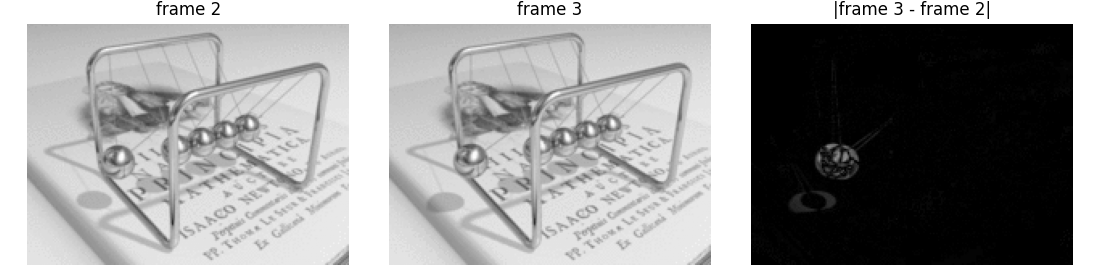

In [4]:
diff = np.abs(np.diff(video, axis=0))        # shape (frames - 1, rows, cols)
print("diff shape:", diff.shape)

k = 2
fig, axes = plt.subplots(1, 3, figsize=(11, 2.8))
for ax, image, title in zip(axes, [video[k], video[k + 1], diff[k]],
                            [f"frame {k}", f"frame {k + 1}", f"|frame {k + 1} - frame {k}|"]):
    ax.imshow(image, cmap="gray", vmin=0, vmax=255)
    ax.set_title(title)
    ax.axis("off")
fig.tight_layout()

The bright patch is the moving ball, in both its old and new spots. Fainter changes come from its string and its shadow on the book, which move too.

## Threshold and find the centroid

A threshold turns every difference frame into a mask. We average the row and column indices of the `True` pixels. If only a handful of pixels changed, we treat that frame as "no detection" and record `NaN`.

In [5]:
threshold = 40
min_pixels = 20
masks = diff > threshold

track_r = np.full(n_frames - 1, np.nan)
track_c = np.full(n_frames - 1, np.nan)
for k in range(n_frames - 1):
    r_idx, c_idx = np.nonzero(masks[k])
    if r_idx.size >= min_pixels:
        track_r[k], track_c[k] = r_idx.mean(), c_idx.mean()

print("frames with no detection:", np.flatnonzero(np.isnan(track_r)))

frames with no detection: [ 8  9 26 27]


## Plot the track

Drawing the centroids on the first frame shows the two arcs, the left ball swinging out and back and then the right ball doing the same.

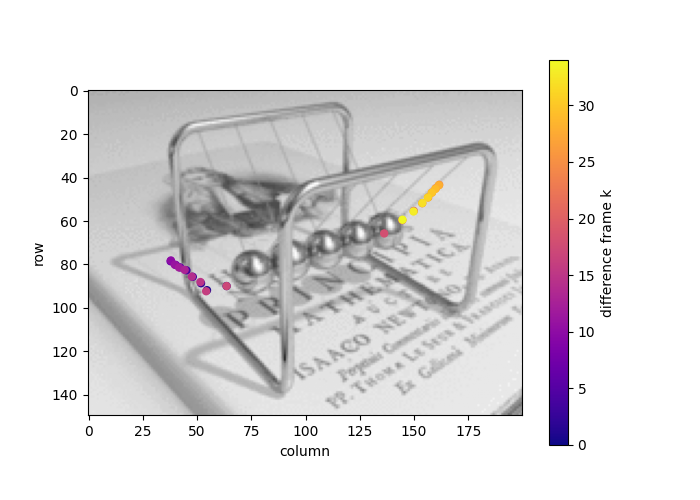

In [6]:
fig, ax = plt.subplots(figsize=(7, 5))
ax.imshow(video[0], cmap="gray", vmin=0, vmax=255)
pts = ax.scatter(track_c, track_r, c=np.arange(n_frames - 1), cmap="plasma", s=25)
fig.colorbar(pts, ax=ax, label="difference frame k")
ax.set_xlabel("column")
ax.set_ylabel("row");

Plotting the column against frame number turns the video into a time signal: the swing of one ball, a hand-off, then the swing of the other.

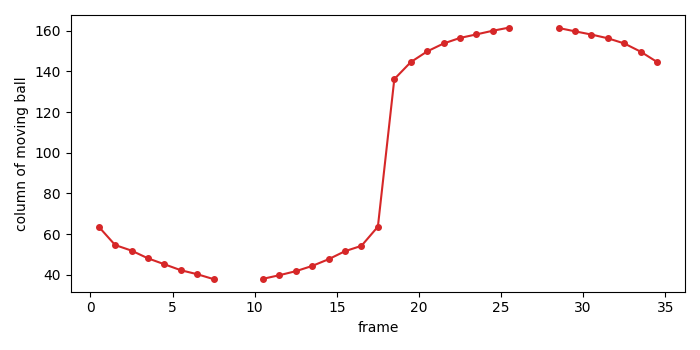

In [7]:
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(np.arange(n_frames - 1) + 0.5, track_c, "o-", color="C3", markersize=4)
ax.set_xlabel("frame")
ax.set_ylabel("column of moving ball")
fig.tight_layout()

## Limitations

Frame differencing only sees **change**. At the top of each swing the ball stops for an instant, consecutive frames are nearly identical, and the track has a gap.
It also mixes the old and new positions, and anything else that moves (the string, the shadow) pulls the centroid along with it.
Background subtraction would fix the first problem, but it needs a picture of the empty scene, and this clip never shows one: every frame has the balls in it.

**Try it:** lower the threshold to 15 and rerun. The shadow and string now take up a bigger share of the mask, and the track drifts away from the ball's center.